## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00334ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d]'
00: =========================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/.
00: Launching 'AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 128 for valuation.
01:   This model has 213633 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_attin-big' epoch 1/1000 error avg trn 284.2; val 50.45/71.71 [1:10 1.1s 0.29s]. LR: 1.00e-03, GN 35.64, excess_weighted: 0.003308/0.003486, excess_weighted_avg: 0.003397/0.003593, excess_spread: 53.67/72.26, excess_spread_

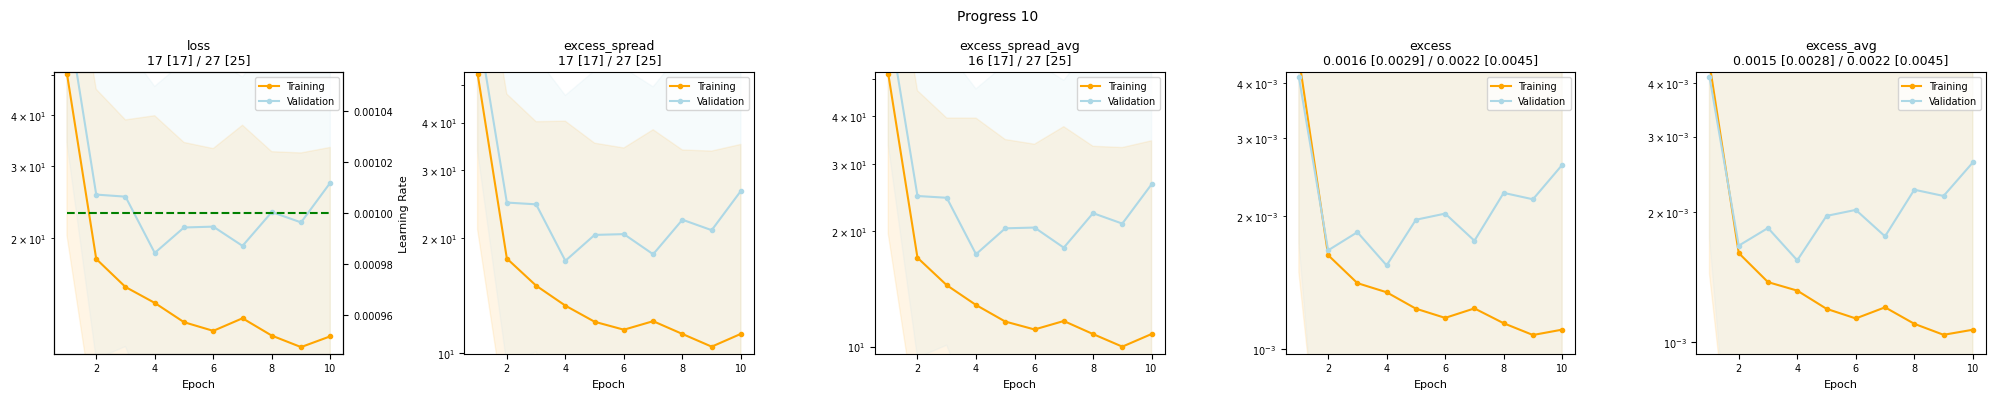

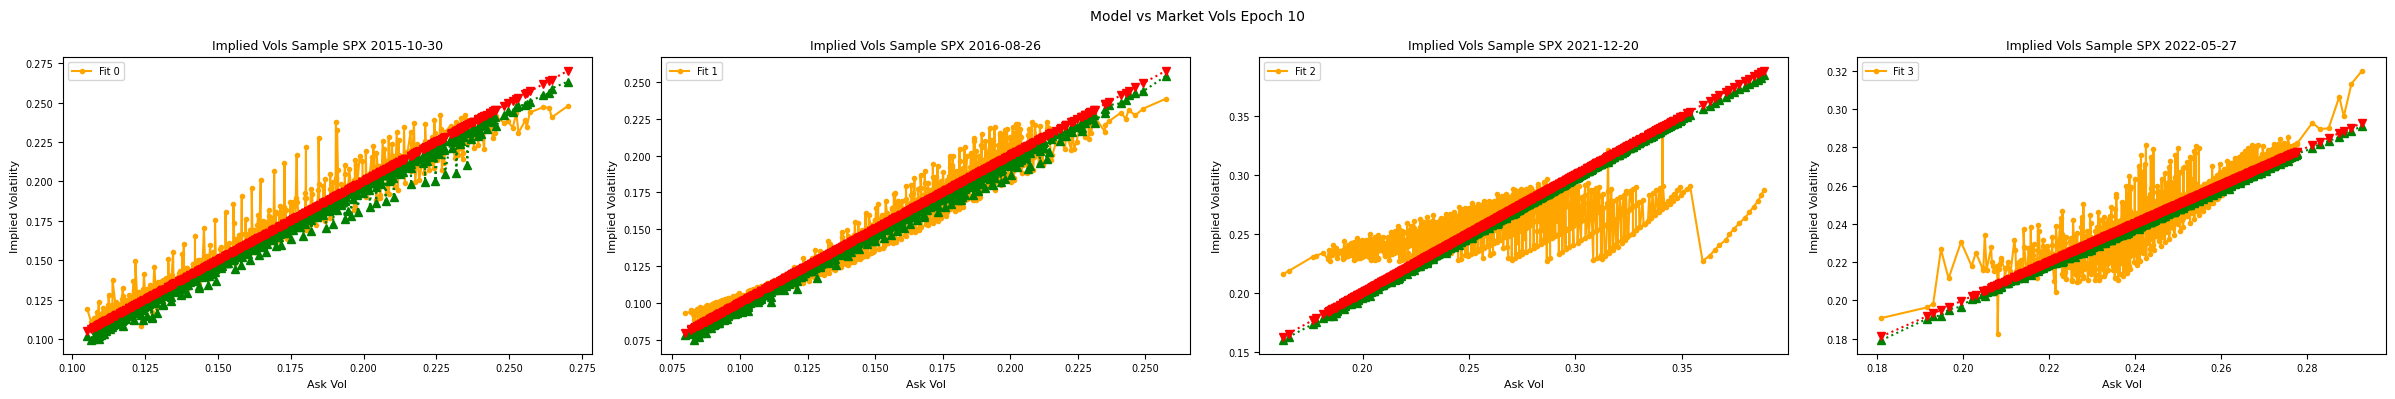

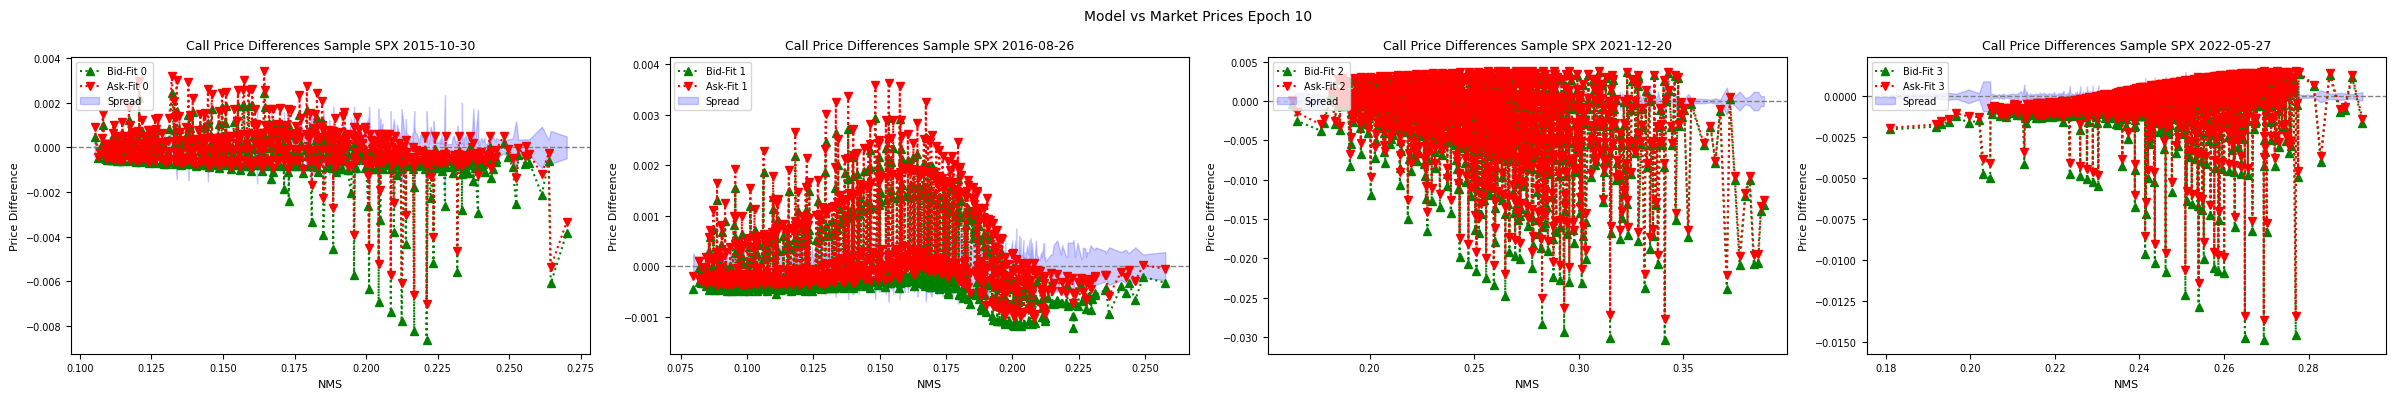

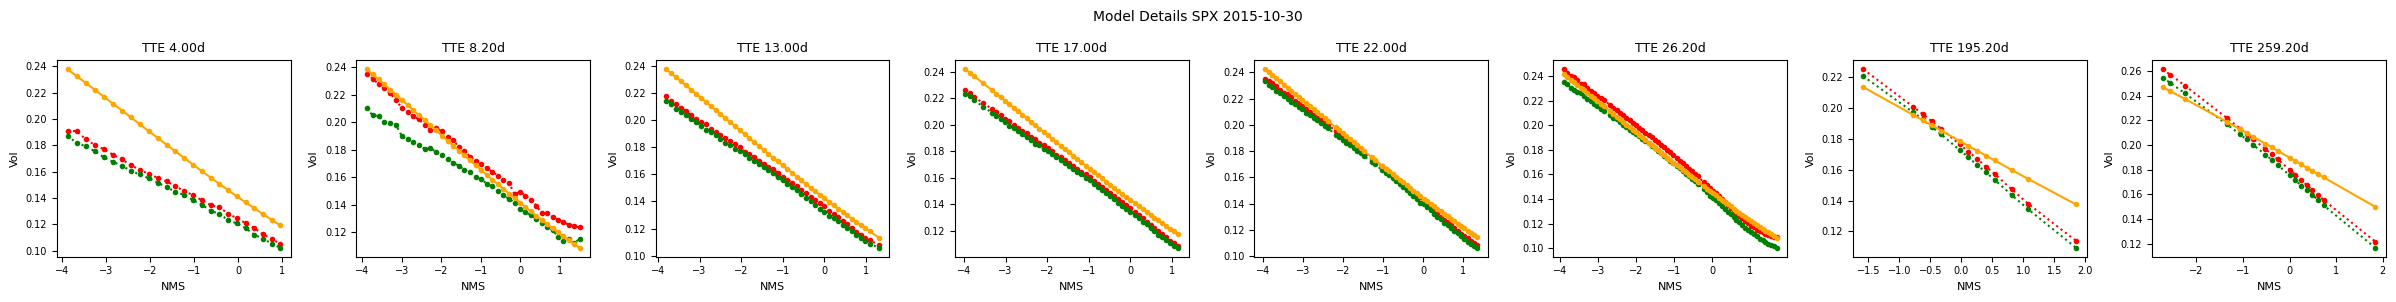

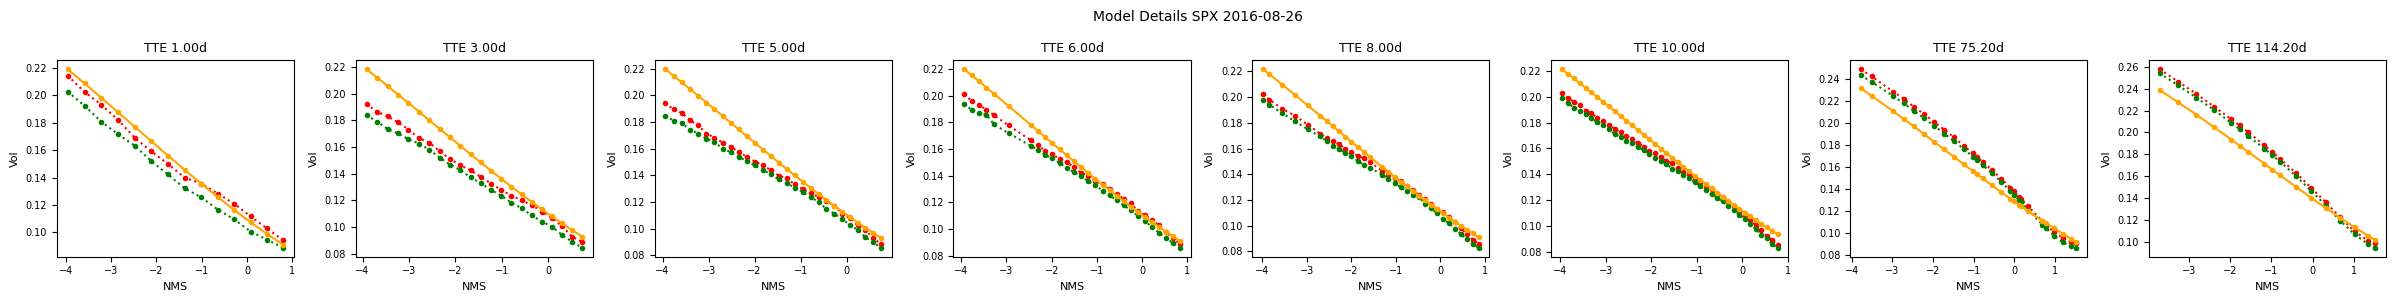

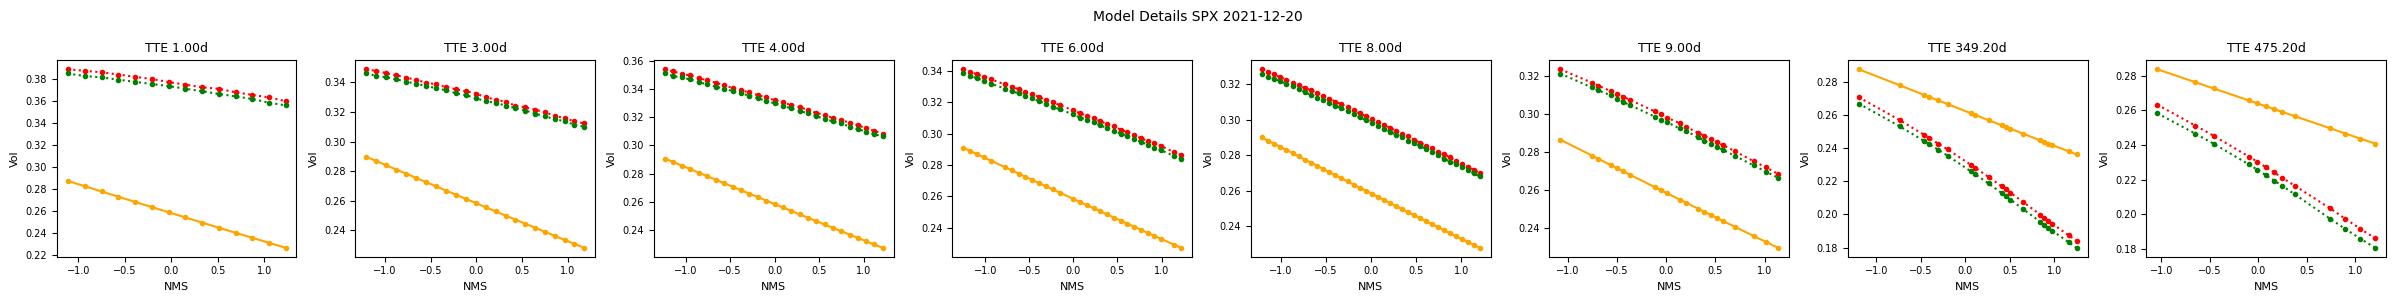

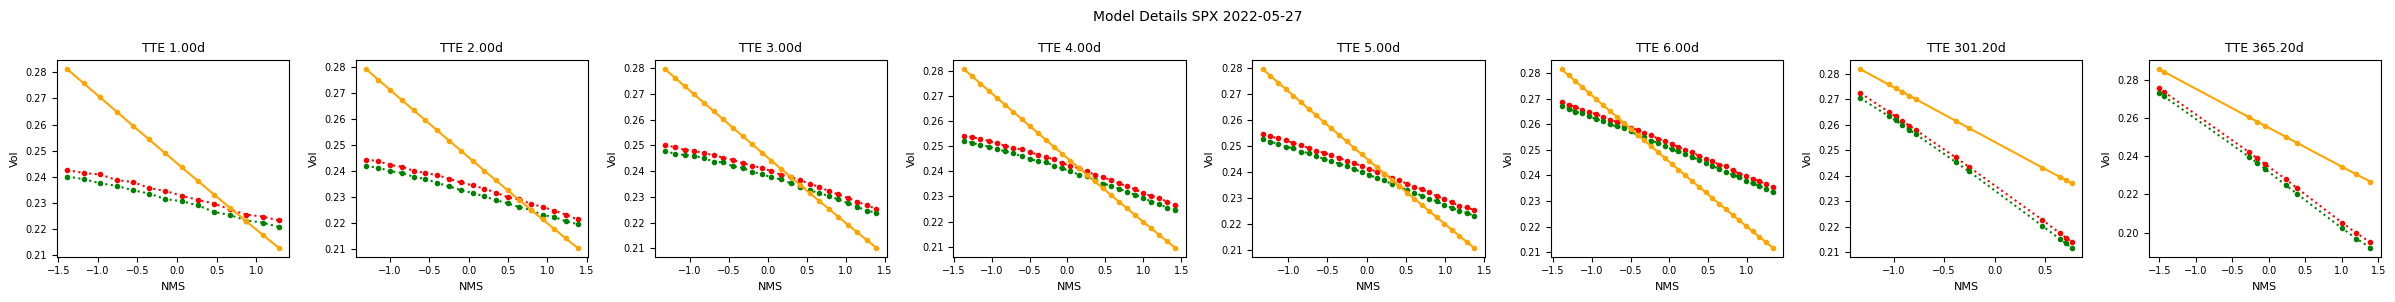

00: Training 'train_vol_vol_attin-big' epoch 2/1000 error avg trn 52.57; val 17.75/25.51 [2:21 1.1s 0.29s]. LR: 1.00e-03, GN 47.11, excess_weighted: 0.001089/0.001193, excess_weighted_avg: 0.00113/0.001311, excess_spread: 17.66/24.73, excess_spread_avg: 17.06/24.73, excess: 0.001633/0.001675, excess_avg: 0.00161/0.001675. ETA: 40:44:08.
01:   Epoch 2: Saving new best validation loss 25.51 vs. 71.71 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/best.pt'... done; this took 0.022s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/last.pt... done; this took 8.11ms.
00: Training 'train_vol_vol_attin-big' epoch 3/1000 error avg trn 17.35; val 15.15/25.22 [3:32 1.1s 0.29s]. LR: 1.00e-03, GN 8.454, excess_weighted: 0.0009249/0.00118, excess_weighted_avg: 0.0009735/0.00132, excess_spread: 15/24.46, excess_spread_avg: 14.46/24.46, excess: 0.

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 128,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 128,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )
